# Phase 7 — Model Explainability and Customer-Level Churn Risk Analysis

This notebook explains the already-fitted, locked Phase 6 model. It does not retrain, tune, recalibrate, or change the model or its operating threshold. Global findings describe predictive dependence; customer-level findings describe model sensitivity. Neither establishes causality or intervention effectiveness.

## 1. Introduction to Explainable AI

Explainable AI methods help people inspect what information a model relies on and why particular predictions respond to customer attributes. Explanations are diagnostic views of a fitted model—not guarantees that the model is correct and not proof that changing an input will change real customer behavior.

## 2. Business importance of explainability

Retention teams need to understand whether risk scores are driven by plausible, available information and where errors occur. Explanations can guide questions for investigation, governance, and future measurement. They do not determine retention ROI, which remains outside Phase 7.

In [1]:
from pathlib import Path
import hashlib
import importlib.util
import json
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import sklearn

CURRENT = Path.cwd().resolve()
ROOT = CURRENT.parent if CURRENT.name == 'notebooks' else CURRENT
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from src.evaluation import compute_classification_metrics, positive_class_probabilities
from src.explainability import (
    anonymized_case_summary, calculate_global_permutation_importance,
    file_sha256, load_trusted_locked_model, local_probability_sensitivity,
    plot_global_importance, plot_local_sensitivity,
    select_representative_cases, summarize_observed_feature_effect,
    summarize_prediction_errors, training_reference_values,
)
from src.preprocessing import (
    CATEGORICAL_FEATURES, IDENTIFIER_COLUMN, NUMERICAL_FEATURES, TARGET_COLUMN,
    apply_deterministic_cleaning, dataframe_fingerprint, load_and_validate_data,
    separate_features_target_ids,
)

RAW_PATH = ROOT / 'data' / 'raw' / 'customer_churn_advanced_dataset.csv'
CLEANED_PATH = ROOT / 'data' / 'processed' / '02_cleaned_dataset.csv'
SPLIT_PATH = ROOT / 'data' / 'processed' / '02_split_indices.json'
MODEL_PATH = ROOT / 'models' / '03_model_artifact.joblib'
METADATA_PATH = ROOT / 'models' / 'final_model_metadata.json'
PHASE6_METRICS_PATH = ROOT / 'reports' / 'evaluation' / 'phase6_final_test_metrics.json'
RESULTS_DIR = ROOT / 'reports' / 'explainability'
FIGURE_DIR = ROOT / 'reports' / 'figures'
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

BLUE = '#3569D4'
PURPLE = '#8051D6'
LIGHT_PURPLE = '#B9A2EA'
sns.set_theme(style='whitegrid', context='talk')
pd.set_option('display.max_columns', 50)
pd.set_option('display.float_format', lambda value: f'{value:,.4f}')

def sha256(path):
    return hashlib.sha256(Path(path).read_bytes()).hexdigest()

def save_figure(fig, filename):
    fig.tight_layout()
    path = FIGURE_DIR / filename
    fig.savefig(path, dpi=160, bbox_inches='tight', facecolor='white')
    plt.show()
    print(f'Saved: {path.relative_to(ROOT)}')

print(f'Python {sys.version.split()[0]}; scikit-learn {sklearn.__version__}')

Python 3.13.3; scikit-learn 1.9.1


## 3. Final model overview

The locked artifact is a sigmoid-calibrated ensemble of five complete pipelines. Each constituent contains the Phase 4 feature engineer, training-fitted preprocessing, and the Phase 5 tuned Random Forest. Joblib artifacts can execute code while loading, so this notebook loads only the known local file after checking its SHA-256 digest against locked metadata.

SHAP is not used: it is not installed in this environment, and the final estimator is a calibrated ensemble rather than a single directly explainable tree. The selected model-agnostic alternatives operate through the complete final estimator.

In [2]:
required = (RAW_PATH, CLEANED_PATH, SPLIT_PATH, MODEL_PATH, METADATA_PATH, PHASE6_METRICS_PATH)
missing = [str(path) for path in required if not path.is_file()]
if missing:
    raise FileNotFoundError(f'Missing Phase 7 prerequisites: {missing}')

raw_hash_before = sha256(RAW_PATH)
cleaned_hash_before = sha256(CLEANED_PATH)
split_hash_before = sha256(SPLIT_PATH)
model_hash_before = sha256(MODEL_PATH)
metadata_hash_before = sha256(METADATA_PATH)

metadata = json.loads(METADATA_PATH.read_text(encoding='utf-8'))
split = json.loads(SPLIT_PATH.read_text(encoding='utf-8'))
phase6_metrics = json.loads(PHASE6_METRICS_PATH.read_text(encoding='utf-8'))
assert metadata['policy_status'] == 'locked before final-test outcome access'
assert metadata['model_artifact_sha256'] == model_hash_before
assert metadata['dataset_fingerprint'] == split['dataset_fingerprint']
assert metadata['calibration']['method'] == 'sigmoid'
locked_threshold = float(metadata['operating_threshold'])

model = load_trusted_locked_model(
    MODEL_PATH,
    expected_sha256=metadata['model_artifact_sha256'],
    trusted=True,
)
assert type(model).__name__ == 'CalibratedClassifierCV'
assert model.classes_.tolist() == [0, 1]
assert len(model.calibrated_classifiers_) == 5

print(f"Final model: {metadata['selected_model']} with {metadata['calibration']['method']} calibration")
print(f'Locked threshold: {locked_threshold:.12f}')
print(f'Artifact digest verified: {model_hash_before}')
print(f"SHAP installed: {importlib.util.find_spec('shap') is not None}")

Final model: Random Forest with sigmoid calibration
Locked threshold: 0.970709000432
Artifact digest verified: b3635a3e65e850bca895a8c7506de6bcd3add2953a3829759544eddede0ed496
SHAP installed: False


## 4. Dataset and evaluation integrity

The exact Phase 2 split and fingerprint are reused. The test set is used only for descriptive, post-evaluation explanation of the locked model. Customer identifiers are separated and never displayed or saved. Baseline predictions are compared with Phase 6 metrics before explanations begin.

In [3]:
cleaned_df = apply_deterministic_cleaning(load_and_validate_data(CLEANED_PATH))
assert dataframe_fingerprint(cleaned_df) == split['dataset_fingerprint']
train_indices = split['train_indices']
test_indices = split['test_indices']
assert len(train_indices) == 960 and len(test_indices) == 240
assert set(train_indices).isdisjoint(test_indices)

train_df = cleaned_df.iloc[train_indices].copy()
test_df = cleaned_df.iloc[test_indices].copy()
X_train, y_train, _train_ids = separate_features_target_ids(train_df)
X_test, y_test, _test_ids = separate_features_target_ids(test_df)
del _train_ids, _test_ids
assert IDENTIFIER_COLUMN not in X_test and TARGET_COLUMN not in X_test

baseline_probabilities = positive_class_probabilities(model, X_test)
baseline_prediction_hash = hashlib.sha256(baseline_probabilities.tobytes()).hexdigest()
baseline_metrics = compute_classification_metrics(
    y_test, baseline_probabilities, threshold=locked_threshold
)
locked_phase6_metrics = phase6_metrics['selected_business_threshold']
for metric in ('accuracy', 'precision', 'recall', 'f1', 'roc_auc', 'average_precision'):
    np.testing.assert_allclose(baseline_metrics[metric], locked_phase6_metrics[metric], rtol=0, atol=1e-15)

integrity = pd.DataFrame({
    'check': ['dataset fingerprint', 'training rows', 'test rows', 'overlap',
              'threshold', 'prediction hash', 'customer IDs in predictors'],
    'value': [split['dataset_fingerprint'], len(X_train), len(X_test),
              len(set(train_indices) & set(test_indices)), locked_threshold,
              baseline_prediction_hash, False],
})
display(integrity)

,check,value
0,dataset fingerprint,df788deba598b73abdc3a41b8a1947af63a90c5f369c2a...
1,training rows,960
2,test rows,240
3,overlap,0
4,threshold,0.9707
5,prediction hash,4e95bae1a6bff60cfdb7a8b2161716e31555cdbcc7ca73...
6,customer IDs in predictors,False


## 5. Global feature importance

Permutation importance measures the decrease in held-out Average Precision when one original input column is shuffled. The complete pipeline remains fitted and unchanged. Ten deterministic repeats (`random_state=42`) provide a mean and standard deviation.

Because shuffling occurs at the raw DataFrame boundary, results refer to original columns—not individual engineered variables or one-hot encoded levels. Correlated inputs can substitute for one another, reducing their apparent individual importance. Negative values are retained and indicate that a shuffle happened to improve the measured score on this finite sample.

In [4]:
global_importance = calculate_global_permutation_importance(
    model,
    X_test,
    y_test,
    n_repeats=10,
    random_state=42,
    scoring='average_precision',
    n_jobs=1,
)
global_importance.to_csv(
    RESULTS_DIR / 'phase7_global_permutation_importance.csv', index=False
)
display(global_importance)

,rank,feature,importance_mean,importance_std,scoring
0,1,monthly_usage_gb,0.1072,0.0164,average_precision
1,2,contract_type,0.0044,0.0026,average_precision
2,3,satisfaction_score,0.0036,0.0010,average_precision
3,4,late_payments_last_12m,0.0017,0.0009,average_precision
4,5,region,0.0006,0.0007,average_precision
5,6,monthly_charges,0.0002,0.0011,average_precision
6,7,discount_pct,0.0002,0.0002,average_precision
7,8,internet_service,0.0002,0.0002,average_precision
8,9,dependents,0.0002,0.0002,average_precision
9,10,paperless_billing,0.0001,0.0003,average_precision


## 6. Feature importance visualization

Bars show mean held-out AP decrease; error bars show one standard deviation across permutations. Larger positive values indicate greater reliance for this test sample. Uncertainty, correlation, and sample size limit fine-grained rank interpretation.

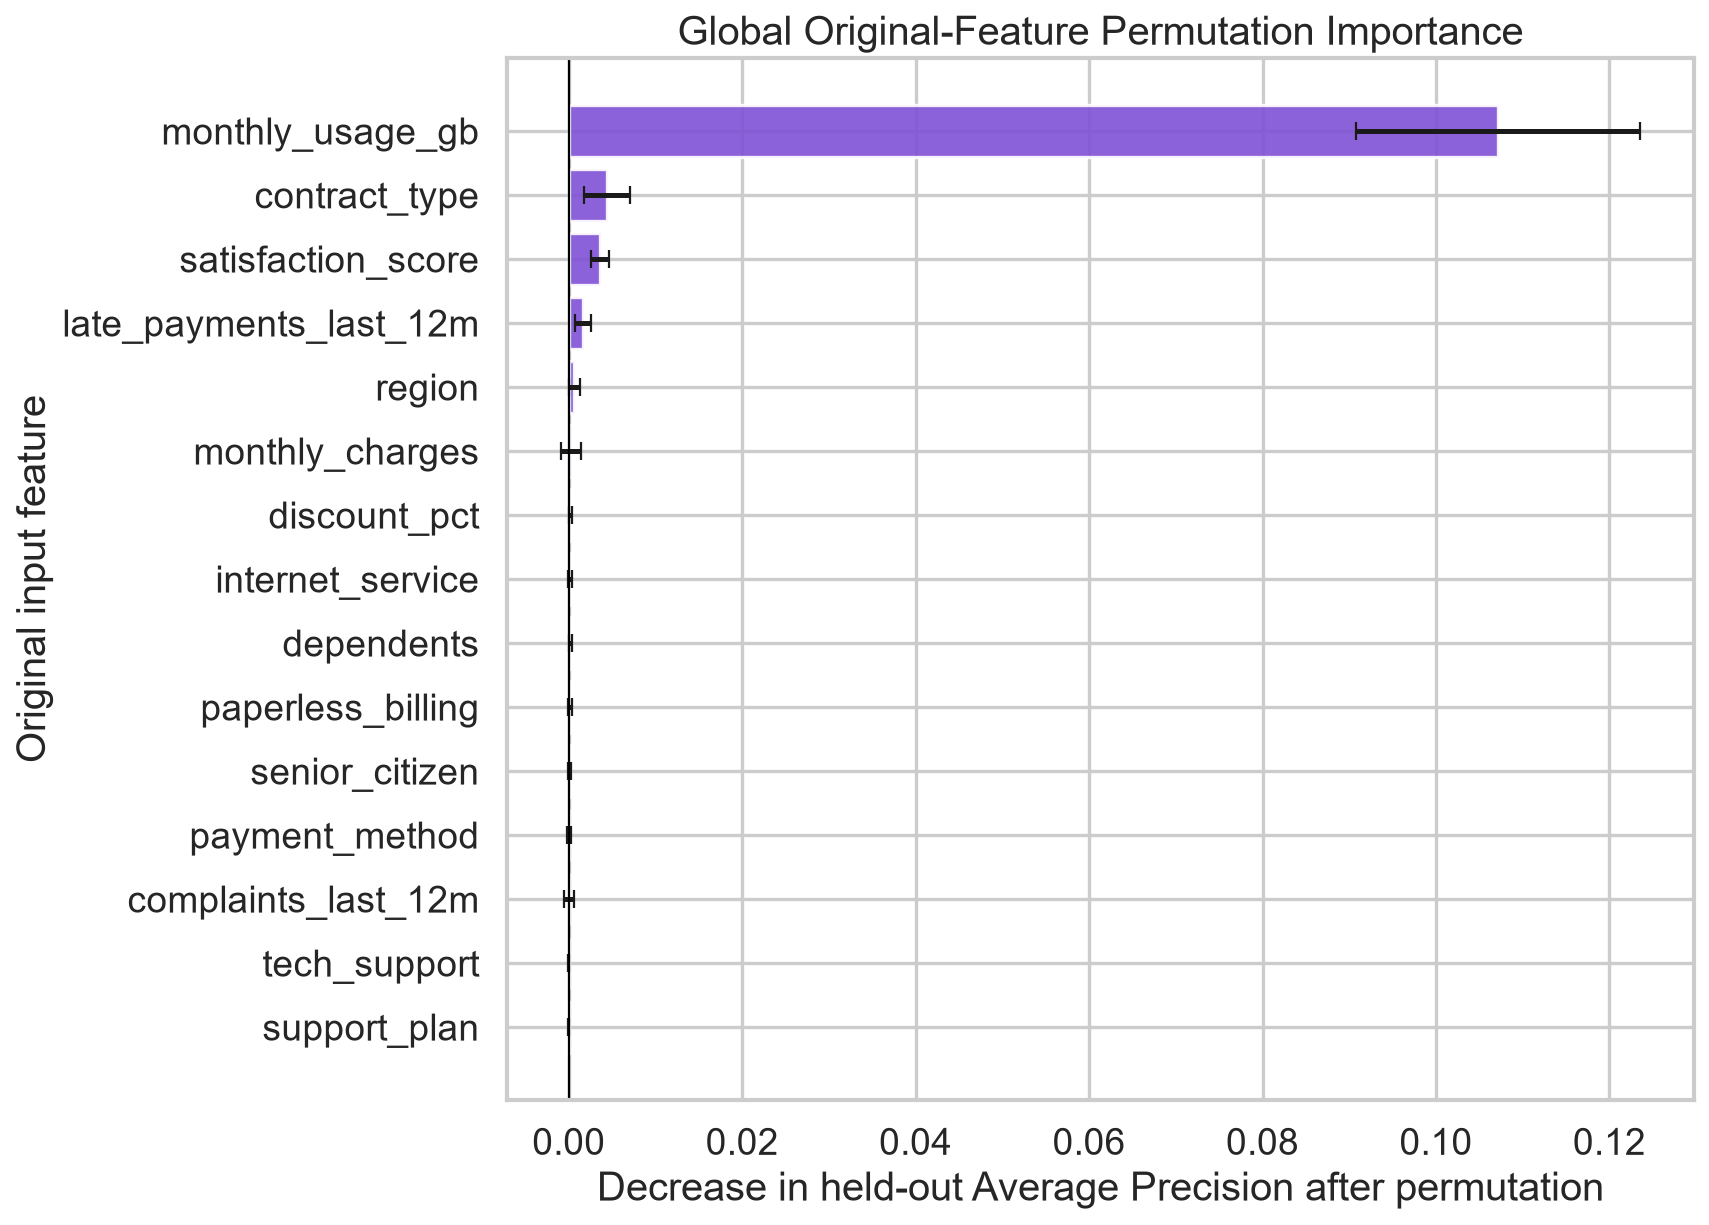

In [5]:
GLOBAL_FIGURE = FIGURE_DIR / 'phase7_global_feature_importance.png'
plot_global_importance(global_importance, GLOBAL_FIGURE, top_n=15)
from IPython.display import Image, display as display_image
display_image(Image(filename=str(GLOBAL_FIGURE)))

## 7. Interpretation of important customer attributes

To show how predictions vary in observed customers without creating synthetic feature combinations, the highest-ranked two numerical features and highest-ranked categorical feature are summarized across test-set groups. These are descriptive prediction summaries, not partial dependence or causal effects; other correlated customer characteristics vary within the groups.

Observed prediction summary: monthly_usage_gb


,feature,group,customer_count,mean_predicted_probability,median_predicted_probability,probability_std
0,monthly_usage_gb,"(1.999, 35.9]",47,0.6300,0.6571,0.1694
1,monthly_usage_gb,"(35.9, 63.48]",44,0.8343,0.9075,0.1812
2,monthly_usage_gb,"(63.48, 78.92]",45,0.9371,0.9710,0.0818
3,monthly_usage_gb,"(78.92, 94.9]",46,0.9757,0.9781,0.0059
4,monthly_usage_gb,"(94.9, 466.9]",45,0.9740,0.9767,0.0074


Observed prediction summary: satisfaction_score


,feature,group,customer_count,mean_predicted_probability,median_predicted_probability,probability_std
0,satisfaction_score,"(0.999, 4.88]",46,0.9239,0.9681,0.1027
1,satisfaction_score,"(4.88, 6.1]",47,0.8830,0.9699,0.1567
2,satisfaction_score,"(6.1, 7.0]",47,0.8607,0.9584,0.1835
3,satisfaction_score,"(7.0, 8.3]",45,0.8655,0.9615,0.1794
4,satisfaction_score,"(8.3, 10.0]",45,0.8446,0.9109,0.1885


Observed prediction summary: contract_type


,feature,group,customer_count,mean_predicted_probability,median_predicted_probability,probability_std
0,contract_type,Month-to-month,146,0.9106,0.9648,0.1209
1,contract_type,One year,58,0.7898,0.9456,0.2339
2,contract_type,Two year,36,0.8465,0.9127,0.1832


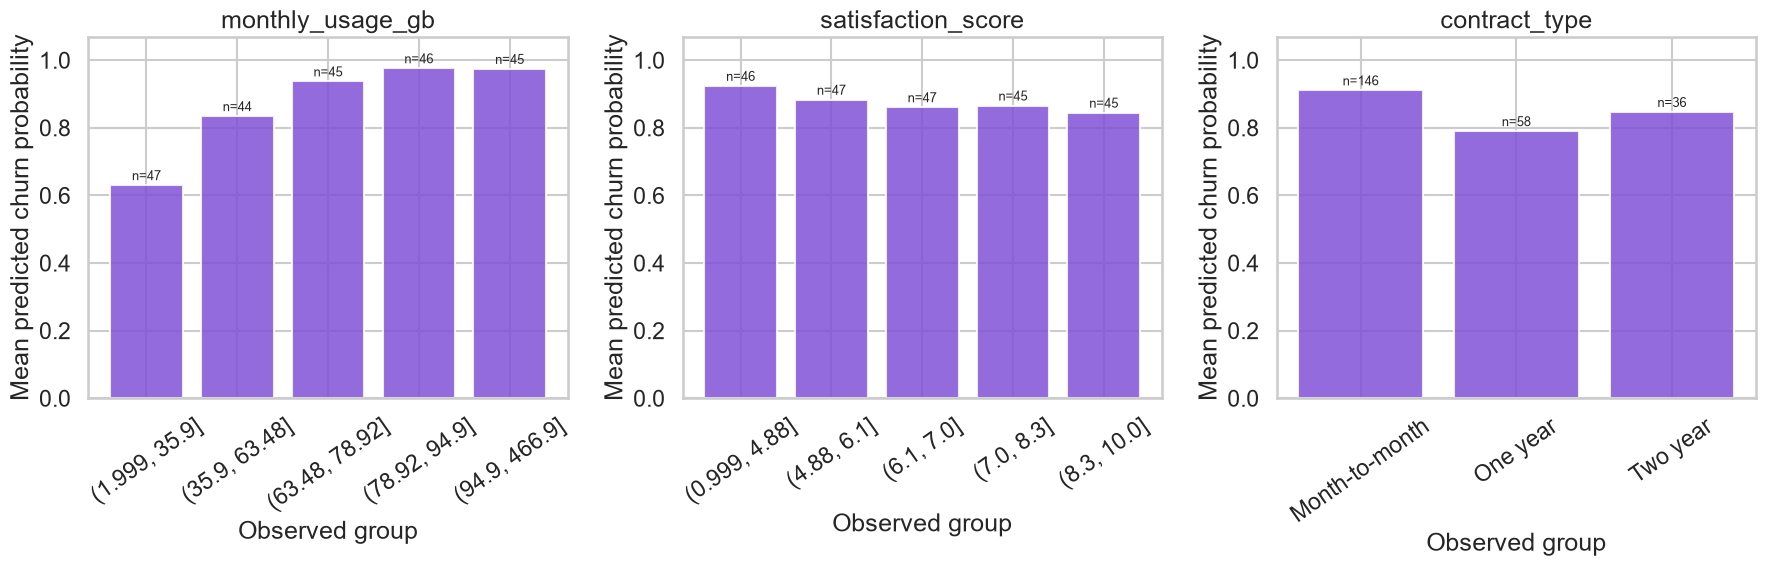

Saved: reports\figures\phase7_feature_effects.png
monthly_usage_gb: observed mean predicted risk ranged from 0.630 ((1.999, 35.9]) to 0.976 ((78.92, 94.9]).
satisfaction_score: observed mean predicted risk ranged from 0.845 ((8.3, 10.0]) to 0.924 ((0.999, 4.88]).
contract_type: observed mean predicted risk ranged from 0.790 (One year) to 0.911 (Month-to-month).


In [6]:
ranked_features = global_importance['feature'].tolist()
top_numerical = [feature for feature in ranked_features if feature in NUMERICAL_FEATURES][:2]
top_categorical = [feature for feature in ranked_features if feature in CATEGORICAL_FEATURES][:1]
effect_features = [*top_numerical, *top_categorical]
assert len(top_numerical) == 2 and len(top_categorical) == 1

effect_tables = {
    feature: summarize_observed_feature_effect(X_test, baseline_probabilities, feature)
    for feature in effect_features
}
feature_effects = pd.concat(effect_tables.values(), ignore_index=True)
feature_effects.to_csv(RESULTS_DIR / 'phase7_feature_effects.csv', index=False)
for feature, table in effect_tables.items():
    print(f'Observed prediction summary: {feature}')
    display(table)

fig, axes = plt.subplots(1, len(effect_features), figsize=(18, 6))
for ax, feature in zip(axes, effect_features):
    table = effect_tables[feature]
    ax.bar(table['group'].astype(str), table['mean_predicted_probability'], color=PURPLE, alpha=0.85)
    for position, row in table.reset_index(drop=True).iterrows():
        ax.text(position, min(row['mean_predicted_probability'] + 0.015, 1.01), f"n={int(row['customer_count'])}", ha='center', fontsize=9)
    ax.set(title=feature, xlabel='Observed group', ylabel='Mean predicted churn probability', ylim=(0, 1.07))
    ax.tick_params(axis='x', rotation=35)
save_figure(fig, 'phase7_feature_effects.png')

for feature, table in effect_tables.items():
    lowest = table.loc[table['mean_predicted_probability'].idxmin()]
    highest = table.loc[table['mean_predicted_probability'].idxmax()]
    print(
        f"{feature}: observed mean predicted risk ranged from "
        f"{lowest['mean_predicted_probability']:.3f} ({lowest['group']}) to "
        f"{highest['mean_predicted_probability']:.3f} ({highest['group']})."
    )

## 8. Individual customer predictions

Three held-out cases are chosen deterministically: a representative true positive, a representative true negative, and the false negative closest to the locked threshold. Labels A–C are anonymized. No raw customer identifier or dataset row index is written to public outputs.

In [7]:
selected_cases = select_representative_cases(
    X_test,
    y_test,
    baseline_probabilities,
    locked_threshold,
    permitted_indices=X_test.index,
)
relevant_features = global_importance.head(8)['feature'].tolist()
public_cases = anonymized_case_summary(selected_cases, X_test, relevant_features)
public_cases.to_csv(RESULTS_DIR / 'phase7_selected_customers.csv', index=False)
display(public_cases)

,customer_label,actual_churn,predicted_probability,threshold,predicted_class,correct_prediction,confusion_category,monthly_usage_gb,contract_type,satisfaction_score,late_payments_last_12m,region,monthly_charges,discount_pct,internet_service
0,Customer A,1,0.9783,0.9707,1,True,true_positive,75.8000,Month-to-month,7.2000,1,Central,46.6300,1.7900,DSL
1,Customer B,0,0.6423,0.9707,0,True,true_negative,35.4000,One year,6.7000,2,Sabaragamuwa,Missing,13.3600,Fiber optic
2,Customer C,1,0.9706,0.9707,0,False,false_negative,76.3000,One year,7.5000,1,North Central,116.0700,13.6000,DSL


## 9. Local customer explanations

For each selected customer, one original feature at a time is replaced with a training-derived reference: the observed value nearest the training median for numerical fields and the training mode for categorical fields. The complete locked model then produces a new probability.

`probability_effect = original probability − reference-replacement probability`. Positive values mean the customer's actual value raises predicted risk relative to that reference; negative values mean it lowers predicted risk. Effects are not additive, are not SHAP values, and are not causal counterfactuals.

Customer A: actual=1, probability=0.9783, predicted=1, category=true_positive


,feature,customer_value,training_reference,original_probability,reference_probability,probability_effect,absolute_effect,direction
0,monthly_usage_gb,75.8000,65.0000,0.9783,0.9311,0.0472,0.0472,actual value raises predicted risk vs reference
1,monthly_charges,46.6300,71.2200,0.9783,0.9770,0.0012,0.0012,actual value raises predicted risk vs reference
2,tenure_months,38,35,0.9783,0.9794,-0.0011,0.0011,actual value lowers predicted risk vs reference
3,satisfaction_score,7.2000,6.8000,0.9783,0.9790,-0.0007,0.0007,actual value lowers predicted risk vs reference
4,paperless_billing,No,Yes,0.9783,0.9789,-0.0007,0.0007,actual value lowers predicted risk vs reference
5,dependents,Yes,No,0.9783,0.9784,-0.0001,0.0001,actual value lowers predicted risk vs reference
6,tech_support,Yes,No,0.9783,0.9784,-0.0001,0.0001,actual value lowers predicted risk vs reference
7,internet_service,DSL,Fiber optic,0.9783,0.9784,-0.0001,0.0001,actual value lowers predicted risk vs reference
8,age,55,47,0.9783,0.9782,0.0001,0.0001,actual value raises predicted risk vs reference
9,discount_pct,1.7900,8.5800,0.9783,0.9782,0.0001,0.0001,actual value raises predicted risk vs reference


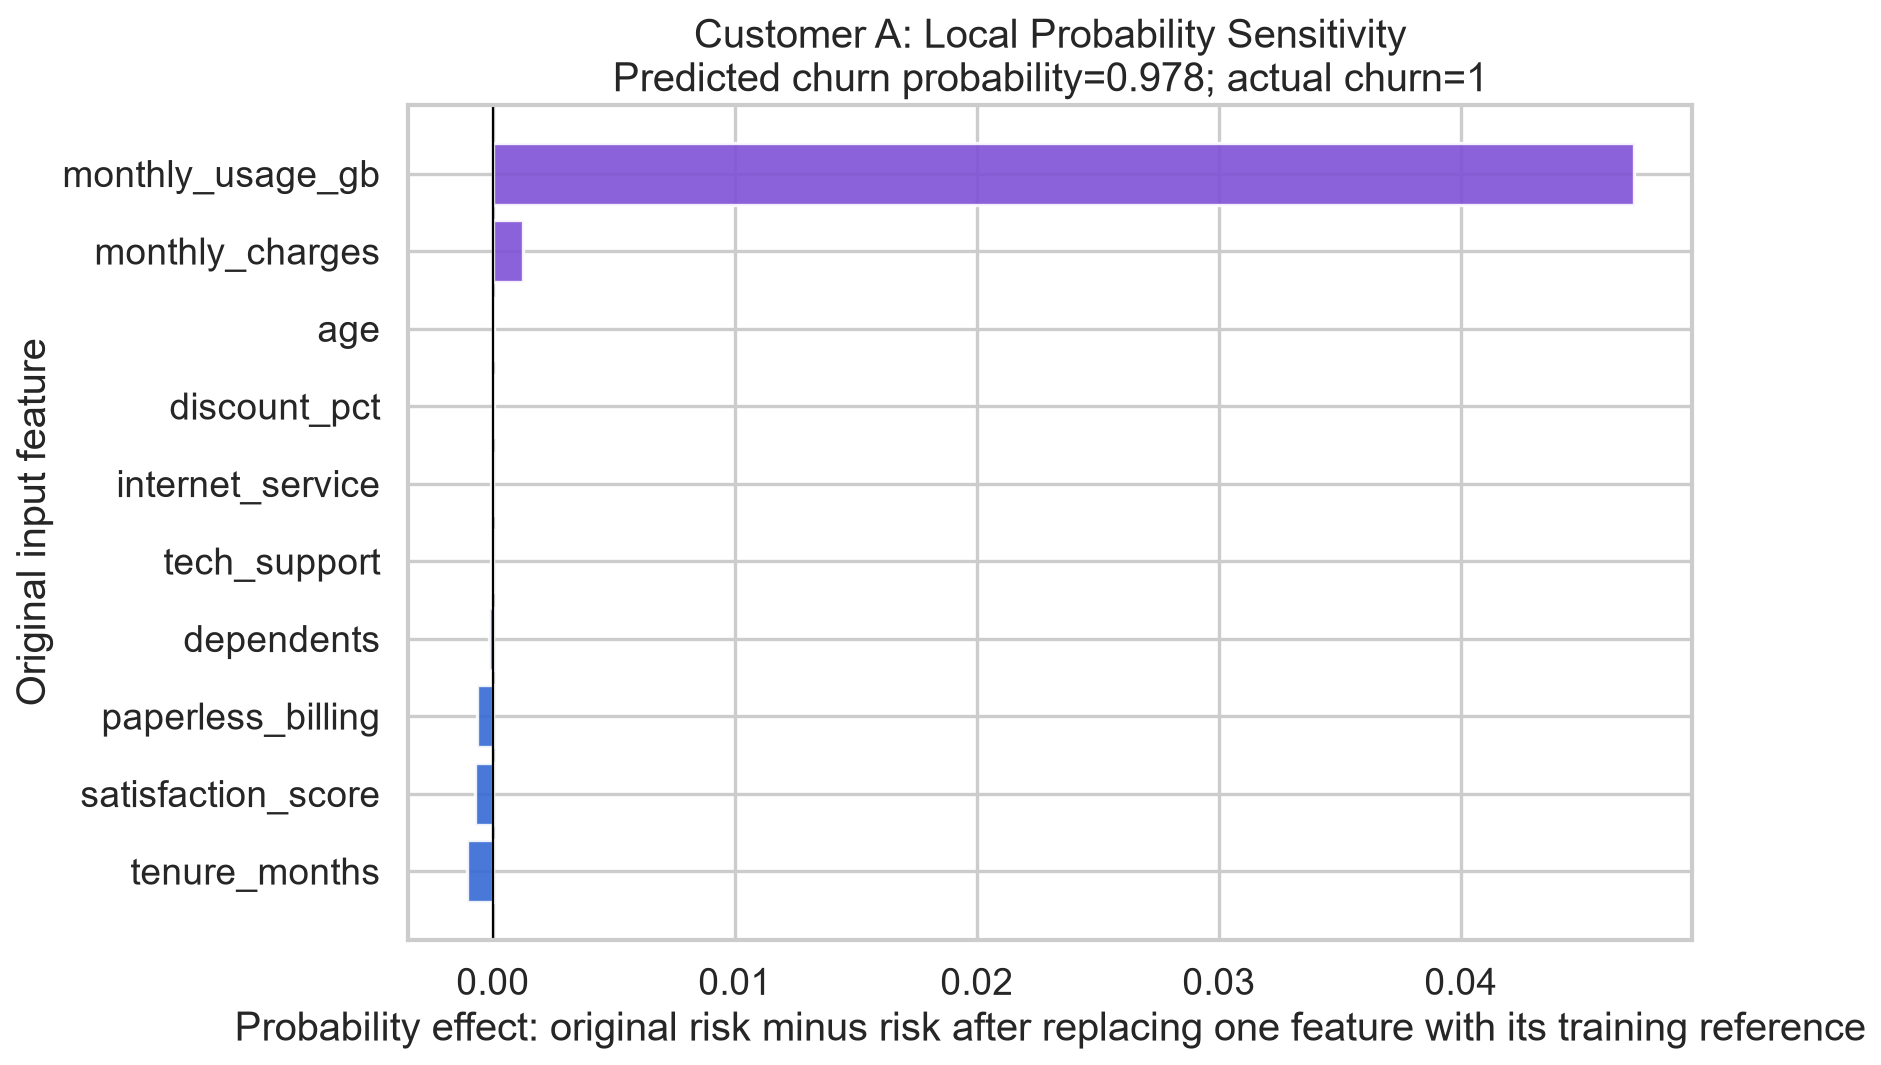

Customer B: actual=0, probability=0.6423, predicted=0, category=true_negative


,feature,customer_value,training_reference,original_probability,reference_probability,probability_effect,absolute_effect,direction
0,contract_type,One year,Month-to-month,0.6423,0.9114,-0.2691,0.2691,actual value lowers predicted risk vs reference
1,monthly_usage_gb,35.4000,65.0000,0.6423,0.8731,-0.2307,0.2307,actual value lowers predicted risk vs reference
2,age,74,47,0.6423,0.4462,0.1961,0.1961,actual value raises predicted risk vs reference
3,monthly_charges,Missing,71.2200,0.6423,0.7560,-0.1137,0.1137,actual value lowers predicted risk vs reference
4,late_payments_last_12m,2,1,0.6423,0.5992,0.0431,0.0431,actual value raises predicted risk vs reference
5,tenure_months,57,35,0.6423,0.6837,-0.0414,0.0414,actual value lowers predicted risk vs reference
6,region,Sabaragamuwa,Central,0.6423,0.6269,0.0154,0.0154,actual value raises predicted risk vs reference
7,satisfaction_score,6.7000,6.8000,0.6423,0.6269,0.0154,0.0154,actual value raises predicted risk vs reference
8,support_plan,Yes,No,0.6423,0.6451,-0.0028,0.0028,actual value lowers predicted risk vs reference
9,total_charges,"2,044.5800","2,176.0600",0.6423,0.6441,-0.0017,0.0017,actual value lowers predicted risk vs reference


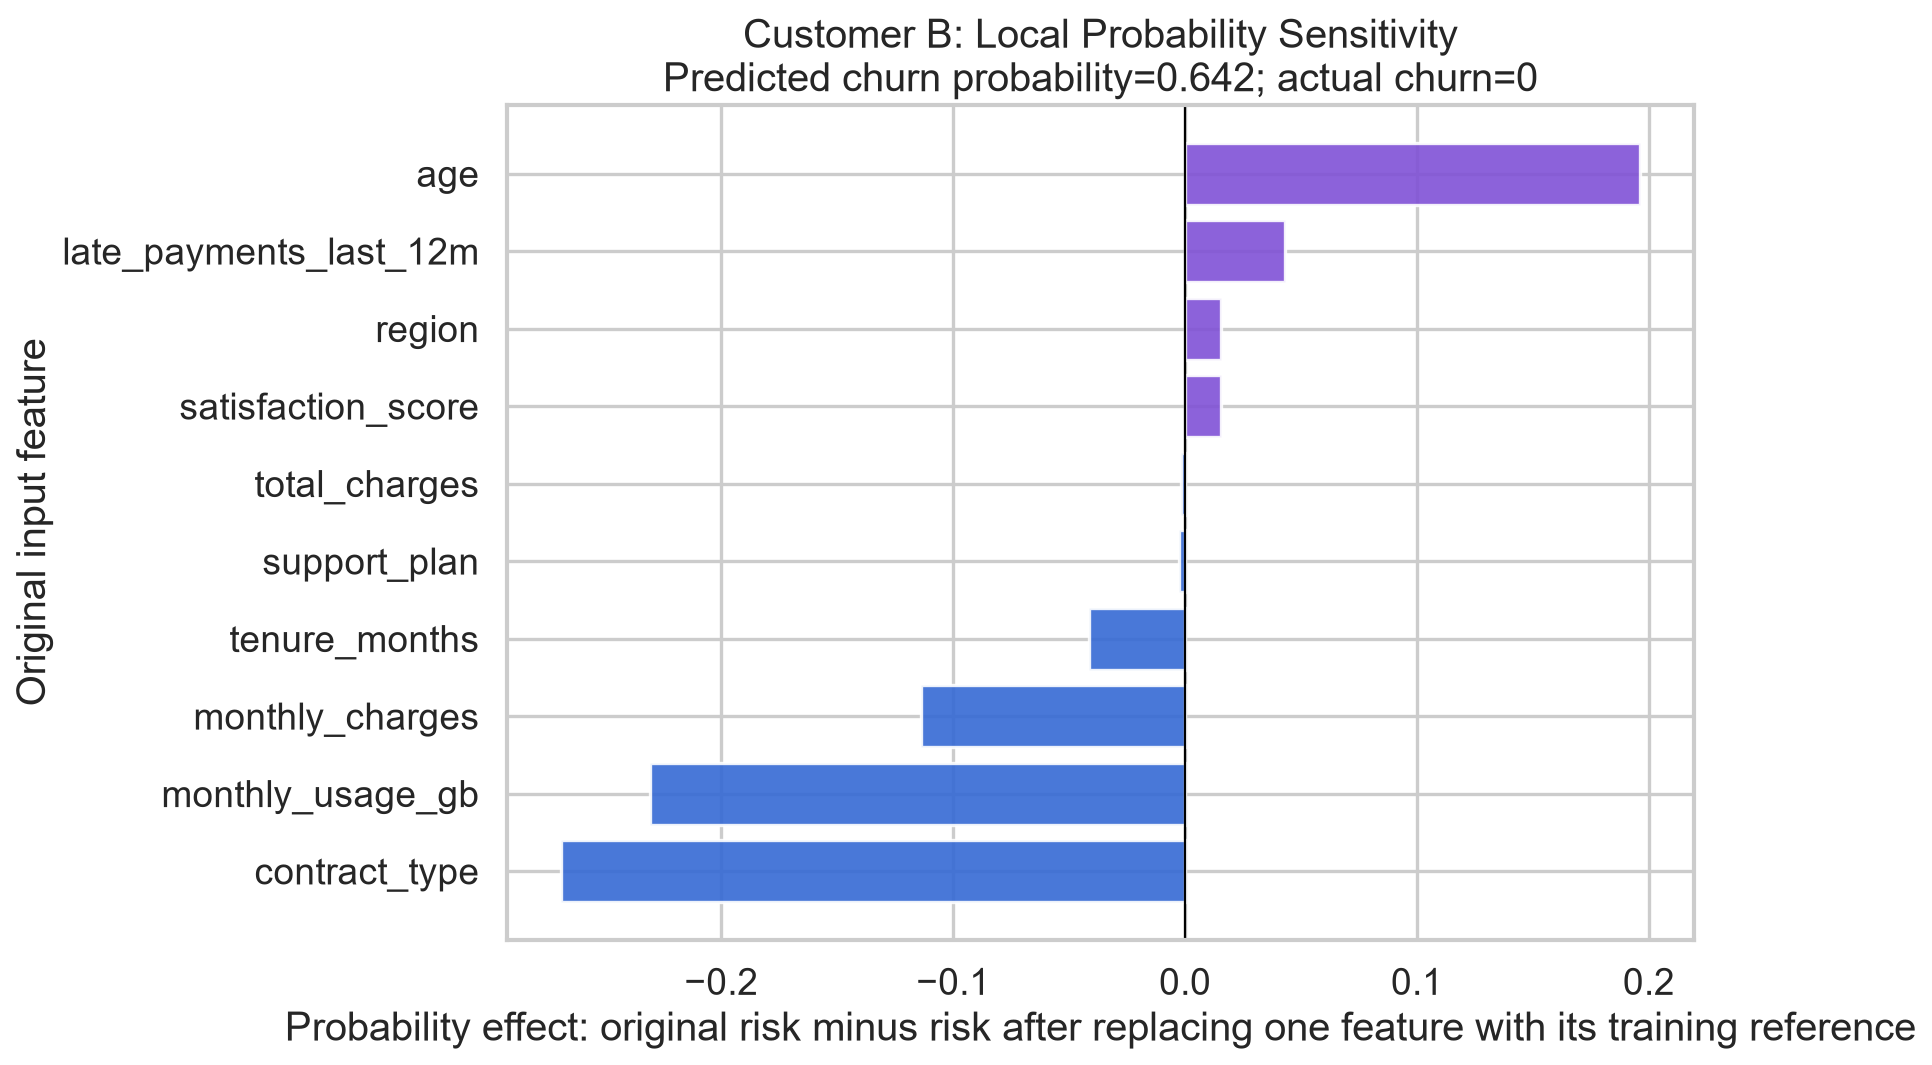

Customer C: actual=1, probability=0.9706, predicted=0, category=false_negative


,feature,customer_value,training_reference,original_probability,reference_probability,probability_effect,absolute_effect,direction
0,monthly_usage_gb,76.3000,65.0000,0.9706,0.8162,0.1544,0.1544,actual value raises predicted risk vs reference
1,monthly_charges,116.0700,71.2200,0.9706,0.9795,-0.0088,0.0088,actual value lowers predicted risk vs reference
2,contract_type,One year,Month-to-month,0.9706,0.9785,-0.0079,0.0079,actual value lowers predicted risk vs reference
3,discount_pct,13.6000,8.5800,0.9706,0.9714,-0.0007,0.0007,actual value lowers predicted risk vs reference
4,satisfaction_score,7.5000,6.8000,0.9706,0.9713,-0.0007,0.0007,actual value lowers predicted risk vs reference
5,region,North Central,Central,0.9706,0.9700,0.0006,0.0006,actual value raises predicted risk vs reference
6,internet_service,DSL,Fiber optic,0.9706,0.9710,-0.0003,0.0003,actual value lowers predicted risk vs reference
7,age,34,47,0.9706,0.9708,-0.0002,0.0002,actual value lowers predicted risk vs reference
8,tenure_months,29,35,0.9706,0.9705,0.0001,0.0001,actual value raises predicted risk vs reference
9,total_charges,"3,261.0600","2,176.0600",0.9706,0.9707,-0.0000,0.0000,actual value lowers predicted risk vs reference


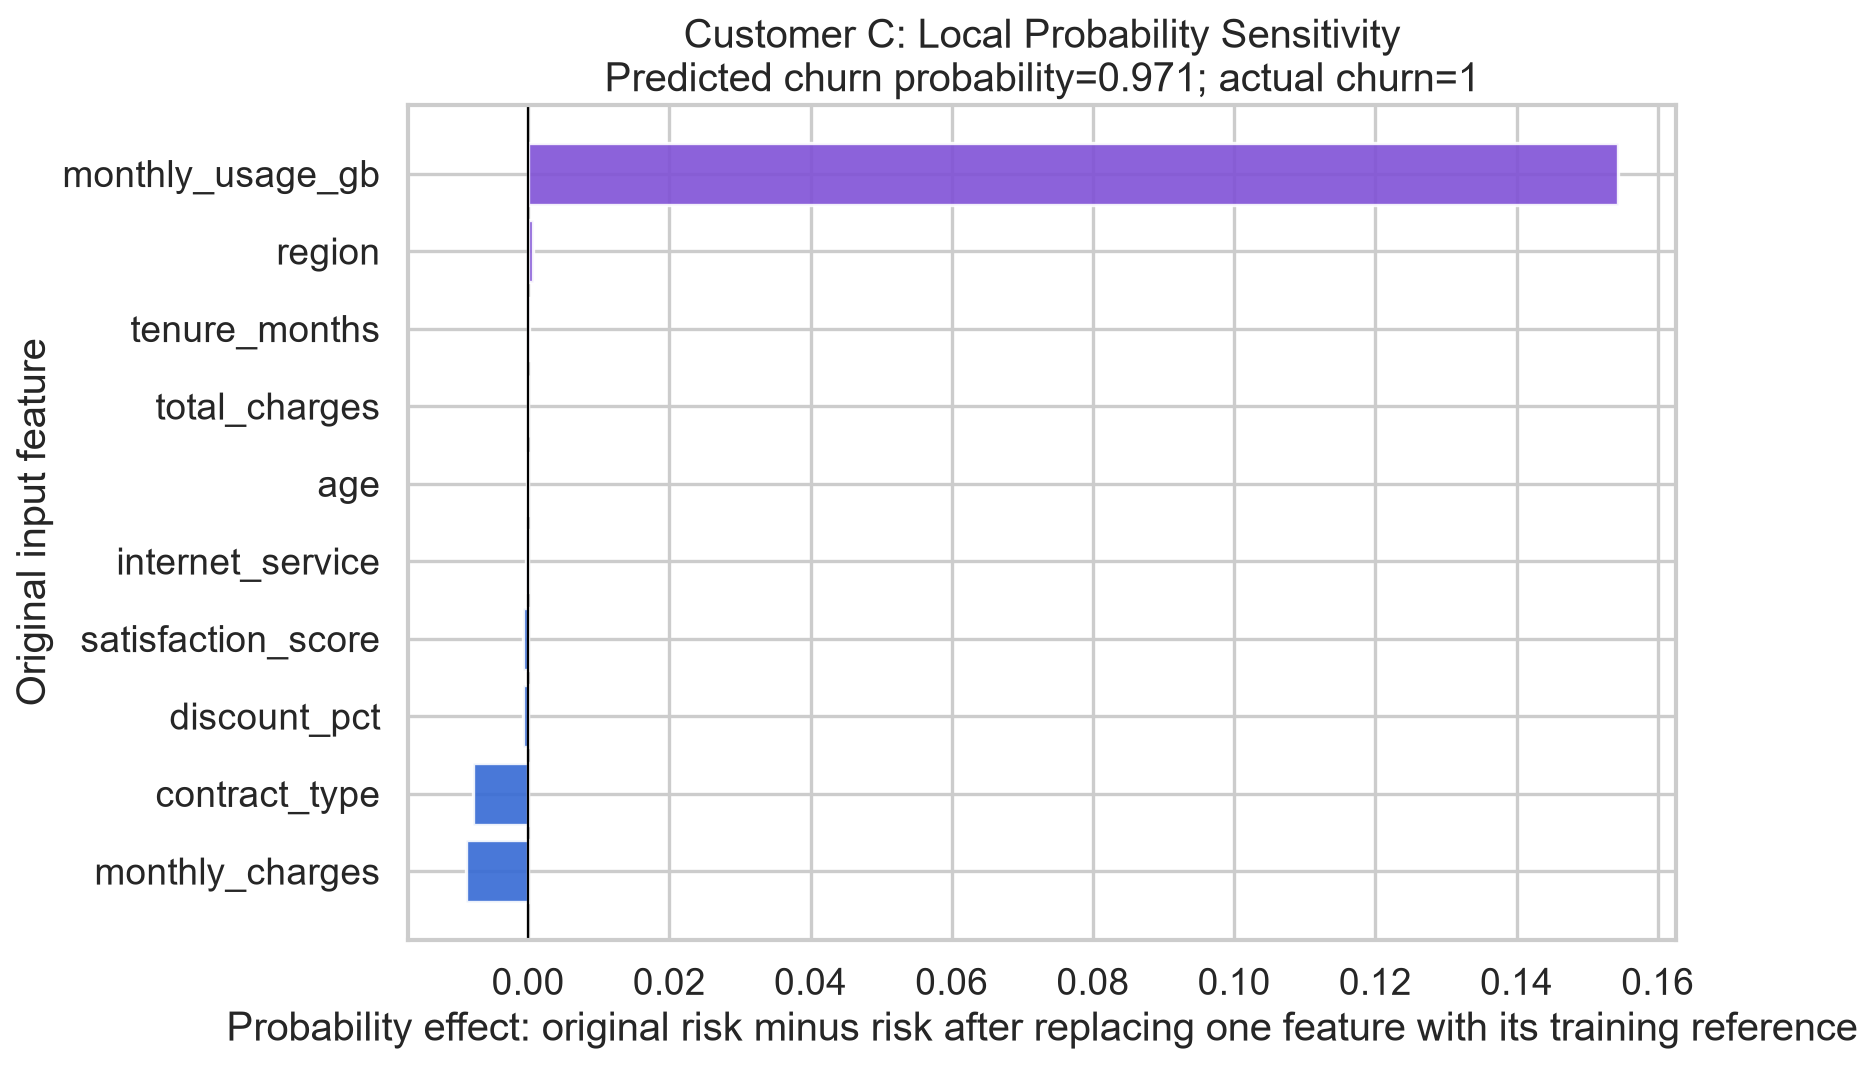

In [8]:
references = training_reference_values(X_train)
local_explanations = {}
for _, case in selected_cases.iterrows():
    label = case['customer_label']
    customer = X_test.loc[[case['_row_index']]]
    explanation = local_probability_sensitivity(model, customer, references)
    local_explanations[label] = explanation
    safe_label = label.split()[-1]
    explanation.to_csv(
        RESULTS_DIR / f'phase7_customer_{safe_label}_sensitivity.csv', index=False
    )
    plot_local_sensitivity(
        explanation,
        FIGURE_DIR / f'phase7_customer_{safe_label}_explanation.png',
        customer_label=label,
        predicted_probability=float(case['predicted_probability']),
        actual_outcome=int(case['actual_churn']),
        top_n=10,
    )
    print(
        f"{label}: actual={int(case['actual_churn'])}, "
        f"probability={case['predicted_probability']:.4f}, "
        f"predicted={int(case['predicted_class'])}, "
        f"category={case['confusion_category']}"
    )
    display(explanation.head(10))
    display_image(Image(filename=str(FIGURE_DIR / f'phase7_customer_{safe_label}_explanation.png')))

## 10. Prediction error analysis

Error categories use the unchanged Phase 6 threshold. Counts must match the final evaluation: 98 true positives, 32 true negatives, 1 false positive, and 109 false negatives. Attribute summaries describe observed differences, not causes of errors. The single false positive is especially unsuitable for generalization.

,confusion_category,customer_count
0,true_positive,98
1,true_negative,32
2,false_positive,1
3,false_negative,109


,confusion_category,feature,non_missing_count,mean,median
0,true_positive,monthly_usage_gb,98,90.9214,90.4000
1,true_positive,satisfaction_score,93,6.2806,6.3000
2,true_positive,late_payments_last_12m,98,0.9082,1.0000
3,true_positive,monthly_charges,98,73.9154,75.4350
4,true_positive,discount_pct,98,8.8674,8.4750
5,true_negative,monthly_usage_gb,30,30.5033,31.4000
6,true_negative,satisfaction_score,30,7.4000,7.3000
7,true_negative,late_payments_last_12m,32,0.5000,0.0000
8,true_negative,monthly_charges,31,70.8013,71.1700
9,true_negative,discount_pct,32,10.4288,10.6050


,confusion_category,feature,value,customer_count,within_category_share
0,true_positive,contract_type,Month-to-month,61,0.6224
1,true_positive,contract_type,One year,23,0.2347
2,true_positive,contract_type,Two year,14,0.1429
3,true_positive,region,North Central,16,0.1633
4,true_positive,region,Western,15,0.1531
5,true_positive,region,Southern,14,0.1429
6,true_positive,region,Eastern,12,0.1224
7,true_positive,region,Sabaragamuwa,9,0.0918
8,true_positive,region,Uva,9,0.0918
9,true_positive,region,Northern,9,0.0918


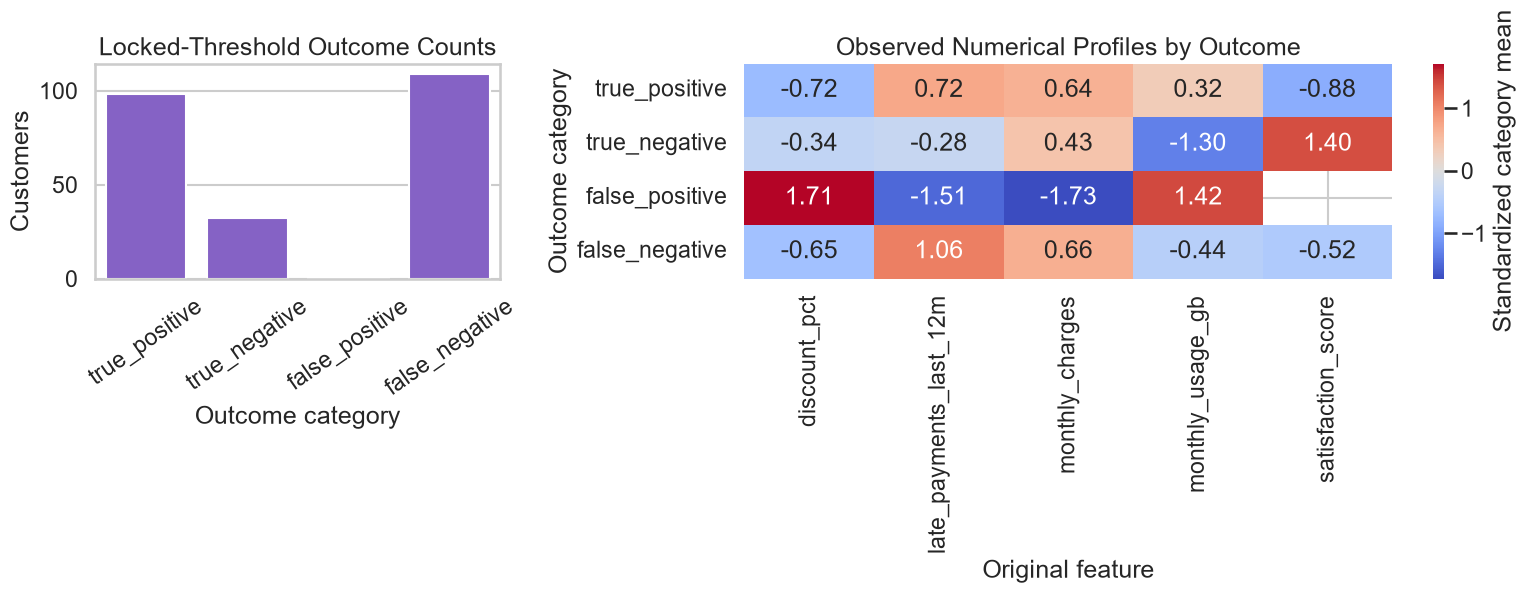

Saved: reports\figures\phase7_prediction_error_analysis.png


In [9]:
error_numerical = [feature for feature in ranked_features if feature in NUMERICAL_FEATURES][:5]
error_categorical = [feature for feature in ranked_features if feature in CATEGORICAL_FEATURES][:3]
error_counts, error_numeric, error_categorical_table = summarize_prediction_errors(
    X_test,
    y_test,
    baseline_probabilities,
    locked_threshold,
    numerical_features=error_numerical,
    categorical_features=error_categorical,
)
expected_counts = {
    'true_positive': 98, 'true_negative': 32,
    'false_positive': 1, 'false_negative': 109,
}
assert error_counts.set_index('confusion_category')['customer_count'].to_dict() == expected_counts
error_counts.to_csv(RESULTS_DIR / 'phase7_error_counts.csv', index=False)
error_numeric.to_csv(RESULTS_DIR / 'phase7_error_numeric_summary.csv', index=False)
error_categorical_table.to_csv(
    RESULTS_DIR / 'phase7_error_categorical_summary.csv', index=False
)
display(error_counts)
display(error_numeric)
display(error_categorical_table)

numeric_pivot = error_numeric.pivot(
    index='confusion_category', columns='feature', values='mean'
).reindex(['true_positive', 'true_negative', 'false_positive', 'false_negative'])
standardized = (numeric_pivot - numeric_pivot.mean()) / numeric_pivot.std(ddof=0).replace(0, 1)
fig, axes = plt.subplots(1, 2, figsize=(16, 6), gridspec_kw={'width_ratios': [1, 2]})
sns.barplot(data=error_counts, x='confusion_category', y='customer_count', color=PURPLE, ax=axes[0])
axes[0].set(title='Locked-Threshold Outcome Counts', xlabel='Outcome category', ylabel='Customers')
axes[0].tick_params(axis='x', rotation=35)
sns.heatmap(standardized, cmap='coolwarm', center=0, annot=True, fmt='.2f', ax=axes[1], cbar_kws={'label': 'Standardized category mean'})
axes[1].set(title='Observed Numerical Profiles by Outcome', xlabel='Original feature', ylabel='Outcome category')
save_figure(fig, 'phase7_prediction_error_analysis.png')

## 11. Feature interactions and limitations

The two most important numerical features are summarized jointly using observed test customers in three quantile groups per feature. This can reveal model-risk patterns that differ across combinations without perturbing inputs into impossible synthetic rows. Sparse cells remain uncertain, correlation and other features can confound the pattern, and no causal interaction is established.

,monthly_usage_gb,satisfaction_score,customer_count,mean_predicted_probability
0,"(1.999, 53.0]","(0.999, 5.8]",24,0.7719
1,"(1.999, 53.0]","(5.8, 7.3]",25,0.6564
2,"(1.999, 53.0]","(7.3, 10.0]",23,0.6717
3,"(53.0, 83.6]","(0.999, 5.8]",24,0.9688
4,"(53.0, 83.6]","(5.8, 7.3]",26,0.9484
5,"(53.0, 83.6]","(7.3, 10.0]",23,0.9090
6,"(83.6, 466.9]","(0.999, 5.8]",29,0.9751
7,"(83.6, 466.9]","(5.8, 7.3]",19,0.9755
8,"(83.6, 466.9]","(7.3, 10.0]",24,0.9734


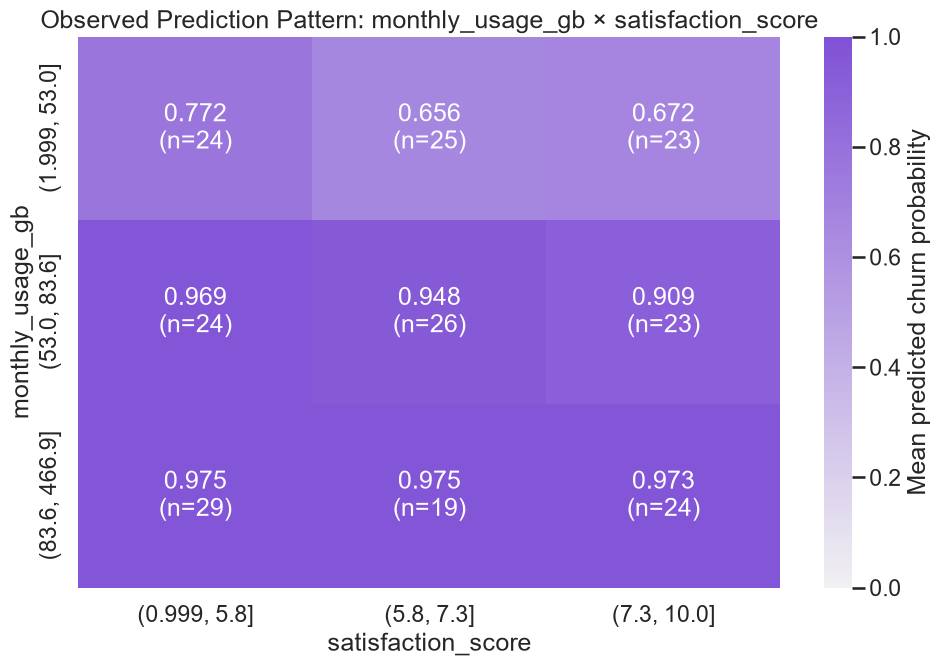

Saved: reports\figures\phase7_observed_feature_interaction.png


In [10]:
interaction_a, interaction_b = top_numerical
interaction_data = pd.DataFrame({
    interaction_a: pd.qcut(pd.to_numeric(X_test[interaction_a], errors='coerce'), q=3, duplicates='drop'),
    interaction_b: pd.qcut(pd.to_numeric(X_test[interaction_b], errors='coerce'), q=3, duplicates='drop'),
    'predicted_probability': baseline_probabilities,
})
interaction_summary = (
    interaction_data.groupby([interaction_a, interaction_b], observed=True)
    .agg(customer_count=('predicted_probability', 'size'), mean_predicted_probability=('predicted_probability', 'mean'))
    .reset_index()
)
interaction_summary[interaction_a] = interaction_summary[interaction_a].astype('string')
interaction_summary[interaction_b] = interaction_summary[interaction_b].astype('string')
interaction_summary.to_csv(RESULTS_DIR / 'phase7_observed_interaction.csv', index=False)
display(interaction_summary)

risk_pivot = interaction_summary.pivot(index=interaction_a, columns=interaction_b, values='mean_predicted_probability')
count_pivot = interaction_summary.pivot(index=interaction_a, columns=interaction_b, values='customer_count')
annotations = risk_pivot.copy().astype(object)
for row in risk_pivot.index:
    for column in risk_pivot.columns:
        risk = risk_pivot.loc[row, column]
        count = count_pivot.loc[row, column]
        annotations.loc[row, column] = '' if pd.isna(risk) else f'{risk:.3f}\n(n={int(count)})'
fig, ax = plt.subplots(figsize=(10, 7))
sns.heatmap(risk_pivot, annot=annotations, fmt='', cmap=sns.light_palette(PURPLE, as_cmap=True), vmin=0, vmax=1, ax=ax, cbar_kws={'label': 'Mean predicted churn probability'})
ax.set(title=f'Observed Prediction Pattern: {interaction_a} × {interaction_b}')
save_figure(fig, 'phase7_observed_feature_interaction.png')

## 12. Business interpretation

High-importance features and high-risk groups identify areas for further business investigation, such as service usage, customer experience, contract structure, or payment behavior—depending on the measured results above. They do not show that changing a field will prevent churn. Local sensitivity can help an analyst understand why a risk score responds to a customer's profile, but it does not measure persuadability or campaign value.

## 13. Explainability limitations

- Permutation importance is predictive, not causal, and correlated inputs can share importance.
- Rankings depend on this 240-row held-out sample and the Average Precision metric.
- Local sensitivity depends on training-derived references and changes one field while holding correlated fields fixed.
- Sensitivity effects do not add to the prediction and are not SHAP values.
- Small groups—especially the single false positive—are unstable.
- Missing or inaccurate inputs, drift, and unverified prediction-time availability affect explanations.
- A high predicted risk does not mean a customer is persuadable or that an intervention will work.

## 14. Summary and conclusions

Phase 7 explains the unchanged calibrated model through raw-input permutation importance, observed-group prediction summaries, anonymized local sensitivity, and locked-threshold error analysis. These results support governance and business questioning while leaving intervention design and economics to Phase 8.

In [11]:
probabilities_after_explanations = positive_class_probabilities(model, X_test)
np.testing.assert_allclose(
    baseline_probabilities, probabilities_after_explanations, rtol=0, atol=0
)
assert hashlib.sha256(probabilities_after_explanations.tobytes()).hexdigest() == baseline_prediction_hash
assert sha256(MODEL_PATH) == model_hash_before == metadata['model_artifact_sha256']
assert sha256(METADATA_PATH) == metadata_hash_before
assert sha256(RAW_PATH) == raw_hash_before
assert sha256(CLEANED_PATH) == cleaned_hash_before
assert sha256(SPLIT_PATH) == split_hash_before
assert float(metadata['operating_threshold']) == locked_threshold

required_figures = [
    'phase7_global_feature_importance.png', 'phase7_feature_effects.png',
    'phase7_customer_A_explanation.png', 'phase7_customer_B_explanation.png',
    'phase7_customer_C_explanation.png', 'phase7_prediction_error_analysis.png',
    'phase7_observed_feature_interaction.png',
]
assert all((FIGURE_DIR / filename).is_file() for filename in required_figures)
assert not public_cases.astype(str).apply(
    lambda column: column.str.contains('customer_id', case=False, regex=False).any()
).any()

integrity_summary = {
    'phase': 7,
    'notebook_completed': True,
    'model_retrained_or_tuned': False,
    'model_artifact_sha256_before': model_hash_before,
    'model_artifact_sha256_after': sha256(MODEL_PATH),
    'model_artifact_unchanged': sha256(MODEL_PATH) == model_hash_before,
    'metadata_unchanged': sha256(METADATA_PATH) == metadata_hash_before,
    'operating_threshold': locked_threshold,
    'threshold_unchanged': float(metadata['operating_threshold']) == locked_threshold,
    'prediction_hash_before': baseline_prediction_hash,
    'prediction_hash_after': hashlib.sha256(probabilities_after_explanations.tobytes()).hexdigest(),
    'predictions_unchanged': bool(np.array_equal(baseline_probabilities, probabilities_after_explanations)),
    'dataset_fingerprint': split['dataset_fingerprint'],
    'raw_dataset_unchanged': sha256(RAW_PATH) == raw_hash_before,
    'cleaned_dataset_unchanged': sha256(CLEANED_PATH) == cleaned_hash_before,
    'split_artifact_unchanged': sha256(SPLIT_PATH) == split_hash_before,
    'global_importance_rows': len(global_importance),
    'anonymized_customers_explained': len(public_cases),
    'customer_identifiers_saved': False,
    'local_method': 'one-feature-at-a-time probability sensitivity against training references',
    'global_method': 'raw-input permutation importance scored by held-out Average Precision',
}
(RESULTS_DIR / 'phase7_integrity.json').write_text(
    json.dumps(integrity_summary, indent=2, sort_keys=True) + '\n', encoding='utf-8'
)

print('Phase 7 verification complete.')
print(f'Global features explained: {len(global_importance)}')
print(f'Anonymized customer cases explained: {len(public_cases)}')
print('Model artifact, threshold, predictions, datasets, and split are unchanged.')
print('No Phase 8 retention simulation or cost-benefit analysis was performed.')

Phase 7 verification complete.
Global features explained: 18
Anonymized customer cases explained: 3
Model artifact, threshold, predictions, datasets, and split are unchanged.
No Phase 8 retention simulation or cost-benefit analysis was performed.
